# 1. Which Output a New LTU Serves

> **Overview.** Each new LTU serves one output, its parent. From the statistics of each output alone, can search find
> the outputs that LTUs can improve, and keep away from the outputs that no LTU can improve?

**Setup.**
- *Problem.* 20 outputs read 400 inputs. The first 2 outputs each read 4 of 8 target LTUs, and each target LTU reads
  10 inputs. The other 18 outputs are decoys, which no LTU can improve: noise of std 1, or a linear function of 10
  inputs plus noise of std 1 (noisy linear). From 200k steps, every 100k steps one decoy becomes a target: it reads 2
  new target LTUs. The outputs that read target LTUs have noise of std 0.1 or 1.
- *Learner.* The learner of `../step_by_step/4_parent_weights.ipynb`: a linear learner and 32 LTUs, except that each
  LTU feeds only its parent, as in a sparse network. Every 10k steps, search replaces the 4 least useful LTUs with new
  LTUs.
- *Parents.* Each new LTU gets a parent output, drawn:
  - uniformly (baseline: the current method);
  - in proportion to the output's error $L_o$, its mean squared error over the last 10k steps (baseline);
  - in proportion to $L_o e_o$, its error times its explained fraction $e_o = (V_o - L_o) / V_o$, where $V_o$ is the
    variance of its targets over the same steps (proposed). Pure noise has an explained fraction of 0;
  - by an oracle, in proportion to $L_o$, but only among the outputs that read target LTUs (reference).
- 5 seeds; 600k steps.

In [1]:
import os
from time import perf_counter
from typing import NamedTuple

os.environ['XLA_PYTHON_CLIENT_PREALLOCATE'] = 'false'   # take GPU memory only as needed, so the GPU can be shared
import jax
jax.config.update('jax_platforms', 'cuda')
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

from phd.jax_core.models import ltu
from phd.jax_core.optimizers.idbd import IDBDState, optax_idbd

%matplotlib inline
assert jax.default_backend() == 'gpu'

/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an 

In [2]:
# --- Problem ---
N_INPUTS = 400
N_TARGETS = 8                        # target LTUs at first
N_SOURCES = 10                       # inputs each target LTU reads, drawn at random
N_OUTPUTS = 20
N_LEARNABLE = 2                      # the first outputs, each reading target LTUs; the rest are decoys
OUTPUT_FAN_IN = 4                    # target LTUs each of them reads, drawn at random
NOISE_STDS = (0.1, 1.0)              # noise on the outputs that read target LTUs: the lowest RMSE possible
N_CHANGES = 4                        # changes: a decoy becomes a target, reading N_NEW new target LTUs
FIRST_CHANGE, CHANGE_EVERY = 200_000, 100_000
N_NEW = 2
N_ALL_TARGETS = N_TARGETS + N_NEW * N_CHANGES

# --- Learner ---
STAT_RATE, VAR_FLOOR = 1e-3, 0.01    # standardization of the LTUs
INIT_STEP_SIZE = 1e-4                # Autostep's initial step-size
META_STEP_SIZE, TAU = 0.02, 1e4
N_LTUS = 32
FAST_STEP_SIZE = 3e-2                # initial step-size of a new LTU's input weights
GROW_Z = 6.0                         # an LTU connects an input whose gradient sum is this many RMS above the rest
FAN_IN = 20                          # a new LTU first reads this many inputs
REPLACED = 4                         # LTUs replaced at each search step, the least useful

# --- Experiment ---
NUM_STEPS = 600_000
WINDOW = 1_000                       # steps per recorded RMSE
N_SEEDS = 5
PERIOD = 10_000                      # steps between search steps
UNIFORM, ERROR, EXPLAINED, ORACLE = range(4)   # how a new LTU's parent output is drawn
NOISE, NOISY_LINEAR = range(2)                 # kinds of decoy

## Target

In [3]:
class Target(NamedTuple):
    w: jax.Array                # (N_ALL_TARGETS, N_INPUTS): the target LTUs' weights, +-1 on the inputs they read
    out: jax.Array              # (N_CHANGES + 1, N_OUTPUTS, N_ALL_TARGETS): the outputs' weights on them, by version
    linear: jax.Array           # (N_CHANGES + 1, N_OUTPUTS, N_INPUTS): the decoys' linear weights, by version
    noise_std: jax.Array        # (N_CHANGES + 1, N_OUTPUTS): each output's noise, by version


def make_target(key, kind, noise_std):
    # Version 0: the first N_LEARNABLE outputs each read OUTPUT_FAN_IN of the first N_TARGETS target LTUs, drawn at
    # random, with random +-1 weights scaled to unit variance, plus noise of std noise_std. The others (decoys) are noise
    # of std 1, plus, if kind is NOISY_LINEAR, a linear function of N_SOURCES random inputs (its own, drawn for every
    # output) with random +-1 weights scaled to unit variance. Each target LTU reads N_SOURCES random inputs, with random
    # +-1 weights. Change c makes version c + 1: a decoy, at random, reads the next N_NEW target LTUs instead, with
    # noise of std noise_std.
    read_key, w_key, out_key, out_w_key, change_key, linear_key, linear_w_key = jax.random.split(key, 7)
    pick = lambda k, shape, n: jnp.argsort(jnp.argsort(jax.random.uniform(k, shape))) < n   # n random entries per row
    w = (jax.random.rademacher(w_key, (N_ALL_TARGETS, N_INPUTS), dtype=float)
         * pick(read_key, (N_ALL_TARGETS, N_INPUTS), N_SOURCES))
    first = jnp.arange(N_OUTPUTS)[:, None] < N_LEARNABLE
    reads = jnp.pad(pick(out_key, (N_OUTPUTS, N_TARGETS), OUTPUT_FAN_IN), ((0, 0), (0, N_ALL_TARGETS - N_TARGETS)))
    out = (jax.random.rademacher(out_w_key, (N_OUTPUTS, N_ALL_TARGETS), dtype=float) * reads * first
           / np.sqrt(OUTPUT_FAN_IN))
    linear = (jax.random.rademacher(linear_w_key, (N_OUTPUTS, N_INPUTS), dtype=float)
              * pick(linear_key, (N_OUTPUTS, N_INPUTS), N_SOURCES) / np.sqrt(N_SOURCES) * (kind == NOISY_LINEAR))
    outs = [out]
    for c in range(N_CHANGES):
        sign_key, decoy_key = jax.random.split(jax.random.fold_in(change_key, c))
        targets = jnp.arange(N_ALL_TARGETS)
        new = (targets >= N_TARGETS + N_NEW * c) & (targets < N_TARGETS + N_NEW * (c + 1))
        decoy = jax.random.categorical(decoy_key, jnp.log(~(out != 0).any(1)))
        out = out.at[decoy].set(jax.random.rademacher(sign_key, (N_ALL_TARGETS,), dtype=float) * new / np.sqrt(N_NEW))
        outs.append(out)
    out = jnp.stack(outs)
    learnable = (out != 0).any(2)
    return Target(w, out, linear * ~learnable[..., None], jnp.where(learnable, noise_std, 1.0))


def sample(target, version, key):
    # One input and its noisy targets, under the given version of the target.
    x_key, noise_key = jax.random.split(key)
    x = jax.random.normal(x_key, (N_INPUTS,))
    return x, (target.out[version] @ jnp.where(target.w @ x > 0, 1.0, -1.0) + target.linear[version] @ x
               + target.noise_std[version] * jax.random.normal(noise_key, (N_OUTPUTS,)))

## Learner

In [4]:
OPTIMIZER = optax_idbd(meta_lr=META_STEP_SIZE, init_lr=INIT_STEP_SIZE, autostep=True, tau=TAU,
                       version='squared_inputs')


@jax.custom_vjp
def standardize(bits, mean, error_mean, error_h_mean):
    return (bits - mean) / jnp.sqrt(jnp.maximum(mean * (1 - mean), VAR_FLOOR))


def standardize_fwd(bits, mean, error_mean, error_h_mean):
    variance = mean * (1 - mean)
    scale = jnp.sqrt(jnp.maximum(variance, VAR_FLOOR))
    h = (bits - mean) / scale
    return h, (h, scale, variance > VAR_FLOOR, error_mean, error_h_mean)


def standardize_bwd(saved, g):
    h, scale, unfloored, error_mean, error_h_mean = saved
    return (g - error_mean - jnp.where(unfloored, h * error_h_mean, 0.)) / scale, None, None, None


standardize.defvjp(standardize_fwd, standardize_bwd)


class Stats(NamedTuple):
    # Running statistics of the LTUs, each shaped (N_LTUS,).
    hidden_mean: jax.Array      # firing rate
    error_mean: jax.Array       # means of the error g arriving at each LTU, and of g * h
    error_h_mean: jax.Array


class Net(NamedTuple):
    # w['hidden'] is the LTUs' weights over [inputs, 1 (the bias)], of which each reads those in `reads`; w['output'] is
    # the outputs' weights over [inputs (the linear learner), LTUs, 1], of which each output reads only its own LTUs.
    w: dict                     # {'hidden': (N_LTUS, N_INPUTS + 1), 'output': (N_OUTPUTS, N_INPUTS + N_LTUS + 1)}
    reads: jax.Array            # shaped like w['hidden']
    opt: IDBDState
    stats: Stats
    shadow: jax.Array           # (N_OUTPUTS, N_LTUS): each LTU's shadow weight, +-1 on one output (its parent), 0 elsewhere
    candidates: jax.Array       # (N_LTUS, N_INPUTS): each LTU's sums of dL/dz * x_i since its last new connection
    loss_sum: jax.Array         # (N_OUTPUTS,): each output's summed squared error since the last search step
    target_sum: jax.Array       # (N_OUTPUTS,): each output's targets, and their squares, summed likewise
    target_sq_sum: jax.Array


def init_net(key):
    # N_LTUS new LTUs with uniform parents, reading random inputs with random signs (no output has weights yet); every
    # other weight 0.
    w = {'hidden': jnp.zeros((N_LTUS, N_INPUTS + 1)), 'output': jnp.zeros((N_OUTPUTS, N_INPUTS + N_LTUS + 1))}
    stats = Stats(jnp.full(N_LTUS, 0.5), jnp.zeros(N_LTUS), jnp.zeros(N_LTUS))
    net = Net(w, jnp.zeros(w['hidden'].shape, bool), OPTIMIZER.init(w), stats, jnp.zeros((N_OUTPUTS, N_LTUS)),
              jnp.zeros((N_LTUS, N_INPUTS)), *(jnp.zeros(N_OUTPUTS),) * 3)
    return rewire(net, key, jnp.ones(N_LTUS, bool), jnp.zeros(N_OUTPUTS), False, False)


def rewire(net, key, replaced, parent_logits, parent, signs):
    # Each `replaced` LTU becomes a new LTU. Its shadow weight, +1 or -1 by slot, goes on its parent, an output drawn
    # with log-probabilities parent_logits. It reads FAN_IN inputs and the bias, the inputs drawn without replacement
    # with probability proportional to the square of the parent's linear weight on each if parent, uniformly otherwise
    # (Gumbel top-k), with LeCun uniform weights, taking the signs of its shadow weight times the parent's linear
    # weights if signs, at step-size FAST_STEP_SIZE. Its output weights are 0, and its statistics, Autostep state and
    # gradient sums fresh.
    out_key, draw_key, w_key = jax.random.split(key, 3)
    sign = jnp.where(jnp.arange(N_LTUS) % 2 == 0, 1.0, -1.0)
    new_parent = jax.random.categorical(out_key, parent_logits, shape=(N_LTUS,))
    shadow = jnp.where(replaced, (jnp.arange(N_OUTPUTS)[:, None] == new_parent) * sign, net.shadow)
    parent_w = shadow.T @ net.w['output'][:, :N_INPUTS]      # each LTU's shadow weight times its parent's linear weights
    scores = jnp.where(parent, jnp.log(parent_w ** 2), 0.0) + jax.random.gumbel(draw_key, parent_w.shape)
    inputs = jnp.argsort(jnp.argsort(-scores)) < FAN_IN
    w = jax.random.uniform(w_key, inputs.shape, minval=-1.0, maxval=1.0) * jnp.sqrt(3.0 / FAN_IN) * inputs
    w = jnp.where(signs, jnp.abs(w) * jnp.sign(parent_w), w)

    where = {'hidden': replaced[:, None],
             'output': jnp.concatenate([jnp.zeros(N_INPUTS, bool), replaced, jnp.zeros(1, bool)])[None]}
    reset = lambda tree, fresh: jax.tree.map(lambda m, a, b: jnp.where(m, a, b), where, fresh, tree)
    zeros = jax.tree.map(jnp.zeros_like, net.w)
    fast = jnp.append(inputs, jnp.zeros((N_LTUS, 1), bool), axis=1)
    beta = {'hidden': jnp.where(fast, jnp.log(FAST_STEP_SIZE), net.opt.init_beta),
            'output': zeros['output'] + net.opt.init_beta}
    opt = net.opt._replace(beta=reset(net.opt.beta, beta), h=reset(net.opt.h, zeros), v=reset(net.opt.v, zeros))
    stats = Stats(*(jnp.where(replaced, fresh, old) for fresh, old in zip((0.5, 0.0, 0.0), net.stats)))
    return net._replace(w=reset(net.w, {'hidden': jnp.append(w, jnp.zeros((N_LTUS, 1)), axis=1),
                                        'output': zeros['output']}),
                        reads=jnp.where(replaced[:, None], jnp.append(inputs, jnp.ones((N_LTUS, 1), bool), axis=1),
                                        net.reads),
                        opt=opt, stats=stats, shadow=shadow, candidates=jnp.where(replaced[:, None], 0.0, net.candidates))


def learn(net, x, y):
    # One online network-Autostep update on half the squared error summed over the outputs, each output reading only
    # its own LTUs, and each LTU's shadow weight standing in for its weight to its parent in the backward pass while the
    # real one is smaller than 1 in magnitude. Returns the new network and each output's squared error on this sample,
    # before learning from it, which it also adds to loss_sum; adds the targets and their squares to target_sum and
    # target_sq_sum, and dL/dz * x_i to each LTU's gradient sums. `probe` is zero; its gradients are the error arriving
    # at each LTU and dL/dz.
    feeds = net.shadow != 0
    mask = jnp.concatenate([jnp.ones((N_OUTPUTS, N_INPUTS), bool), feeds, jnp.ones((N_OUTPUTS, 1), bool)], 1)

    def loss_fn(w, probe):
        b = ltu((w['hidden'] * net.reads) @ jnp.append(x, 1.0) + probe[1])
        mean = net.stats.hidden_mean + STAT_RATE * (jax.lax.stop_gradient(b) - net.stats.hidden_mean)
        a = standardize(b, mean, net.stats.error_mean, net.stats.error_h_mean) + probe[0]
        source = jnp.concatenate([x, a, jnp.ones(1)])
        unit_w = w['output'][:, N_INPUTS:-1]
        back = jax.lax.stop_gradient(jnp.where(feeds & (jnp.abs(unit_w) < 1.0), net.shadow, unit_w)) @ a
        prediction = w['output'] @ jax.lax.stop_gradient(source) + back - jax.lax.stop_gradient(back)
        return 0.5 * jnp.sum((prediction - y) ** 2), (jax.lax.stop_gradient(source), jax.lax.stop_gradient(a), mean,
                                                      jax.lax.stop_gradient(prediction - y) ** 2)

    (_, (source, h, mean, squared)), (grads, (error, dz)) = jax.value_and_grad(loss_fn, (0, 1), has_aux=True)(
        net.w, (jnp.zeros(N_LTUS),) * 2)
    grads = {'hidden': grads['hidden'] * net.reads, 'output': grads['output'] * mask}
    sources = {'hidden': jnp.append(x, 1.0) * net.reads, 'output': source * mask}
    updates, opt = OPTIMIZER.update((grads, None, sources), net.opt, net.w)
    stats = Stats(mean, net.stats.error_mean + STAT_RATE * (error - net.stats.error_mean),
                  net.stats.error_h_mean + STAT_RATE * (error * h - net.stats.error_h_mean))
    return net._replace(w=jax.tree.map(jnp.add, net.w, updates), opt=opt, stats=stats,
                        candidates=net.candidates + dz[:, None] * x, loss_sum=net.loss_sum + squared,
                        target_sum=net.target_sum + y, target_sq_sum=net.target_sq_sum + y ** 2), squared


def grow(net):
    # Each LTU whose largest gradient sum, over the inputs it does not read, is more than GROW_Z times their root mean
    # square connects that input, at weight 0 with step-size FAST_STEP_SIZE, and restarts its sums.
    unread = ~net.reads[:, :N_INPUTS]
    sums = jnp.where(unread, jnp.abs(net.candidates), 0.0)
    rms = jnp.sqrt(jnp.sum(sums ** 2, 1) / unread.sum(1))
    grows = jnp.max(sums, 1) > GROW_Z * rms
    new = (jnp.arange(N_INPUTS + 1) == jnp.argmax(sums, 1)[:, None]) & grows[:, None]
    beta = jnp.where(new, jnp.log(FAST_STEP_SIZE), net.opt.beta['hidden'])
    return net._replace(w={**net.w, 'hidden': jnp.where(new, 0.0, net.w['hidden'])}, reads=net.reads | new,
                        opt=net.opt._replace(beta={**net.opt.beta, 'hidden': beta}),
                        candidates=jnp.where(grows[:, None], 0.0, net.candidates))


def usefulness(net):
    # Each LTU's squared weight to its parent, its only output: about the increase in its parent's squared error if it
    # were removed (its activity has unit variance).
    return (net.w['output'][:, N_INPUTS:-1] ** 2).sum(0)


def parent_logits(net, rule, learnable):
    # Log-probabilities of each output being a new LTU's parent: uniform; or in proportion to its mean squared error L
    # over the last search period (ERROR), times its explained fraction (V - L) / V, with V its targets' variance and
    # 0 if negative (EXPLAINED), or among only the outputs reading target LTUs (ORACLE). Uniform if all are 0.
    loss = net.loss_sum / PERIOD
    variance = net.target_sq_sum / PERIOD - (net.target_sum / PERIOD) ** 2
    explained = jnp.maximum(variance - loss, 0.0) / jnp.maximum(variance, 1e-30)
    weight = jnp.select([rule == ERROR, rule == EXPLAINED, rule == ORACLE],
                        [loss, loss * explained, loss * learnable], jnp.ones(N_OUTPUTS))
    return jnp.log(jnp.where(weight.sum() > 0, weight, 1.0))

## Training

In [5]:
def pick(condition, a, b):
    # a where condition holds, b otherwise, for networks.
    return jax.tree.map(lambda u, v: jnp.where(condition, u, v), a, b)


def train(net, key, target, rule):
    # NUM_STEPS online network-Autostep steps on samples from `target`, its version changing at FIRST_CHANGE and every
    # CHANGE_EVERY steps after. The LTUs grow every WINDOW steps, and every PERIOD steps the REPLACED least useful LTUs
    # are replaced by new ones with parents drawn by `rule`, and the outputs' statistics restart. Returns, for each
    # window, the mean squared error over the outputs then reading target LTUs.

    def window(net, inputs):
        index, key = inputs
        version = jnp.clip((index * WINDOW - FIRST_CHANGE) // CHANGE_EVERY + 1, 0, N_CHANGES)
        learnable = (target.out[version] != 0).any(1)
        sample_key, wire_key = jax.random.split(key)
        net, squared = jax.lax.scan(lambda net, k: learn(net, *sample(target, version, k)), net,
                                    jax.random.split(sample_key, WINDOW))
        net = grow(net)
        weakest = jnp.zeros(N_LTUS, bool).at[jnp.argsort(usefulness(net))[:REPLACED]].set(True)
        new = rewire(net, wire_key, weakest, parent_logits(net, rule, learnable), True, True)
        zero = jnp.zeros(N_OUTPUTS)
        net = pick((index + 1) * WINDOW % PERIOD == 0,
                   new._replace(loss_sum=zero, target_sum=zero, target_sq_sum=zero), net)
        squared = squared.mean(0)
        return net, (squared * learnable).sum() / learnable.sum()

    n = NUM_STEPS // WINDOW
    return jax.lax.scan(window, net, (jnp.arange(n), jax.random.split(key, n)))[1]


def run(configs):
    # Each (decoy kind, noise std, rule) of configs on N_SEEDS seeds, vmapped together; seed s gives every run the same
    # target LTUs and inputs. Returns {config: the RMSE over the outputs then reading target LTUs, (seed, window)}.
    kind, noise, rule, seed = (jnp.array(v) for v in zip(*[(*c, s) for c in configs for s in range(N_SEEDS)]))
    keys = lambda k: jax.random.split(jax.random.PRNGKey(k), N_SEEDS)[seed]
    targets = jax.vmap(make_target)(keys(2), kind, noise)
    mse = jax.jit(jax.vmap(train))(jax.vmap(init_net)(keys(0)), keys(1), targets, rule)
    return dict(zip(configs, np.sqrt(np.asarray(mse)).reshape(len(configs), N_SEEDS, -1)))

## Runs

In [6]:
DECOYS = [(NOISE, 'noise decoys'), (NOISY_LINEAR, 'noisy linear decoys')]
RULES = [('uniform', 'baseline: current method', UNIFORM, 'tab:red'),
         ('error', 'baseline', ERROR, 'tab:orange'),
         ('error times explained fraction', 'proposed', EXPLAINED, 'tab:blue'),
         ('oracle', 'reference: error, among only the outputs reading target LTUs', ORACLE, 'tab:gray')]
started = perf_counter()
results = run([(kind, noise, rule) for kind, _ in DECOYS for noise in NOISE_STDS for _, _, rule, _ in RULES])
print(f'{len(results) * N_SEEDS} runs in {perf_counter() - started:.0f}s')

80 runs in 52s


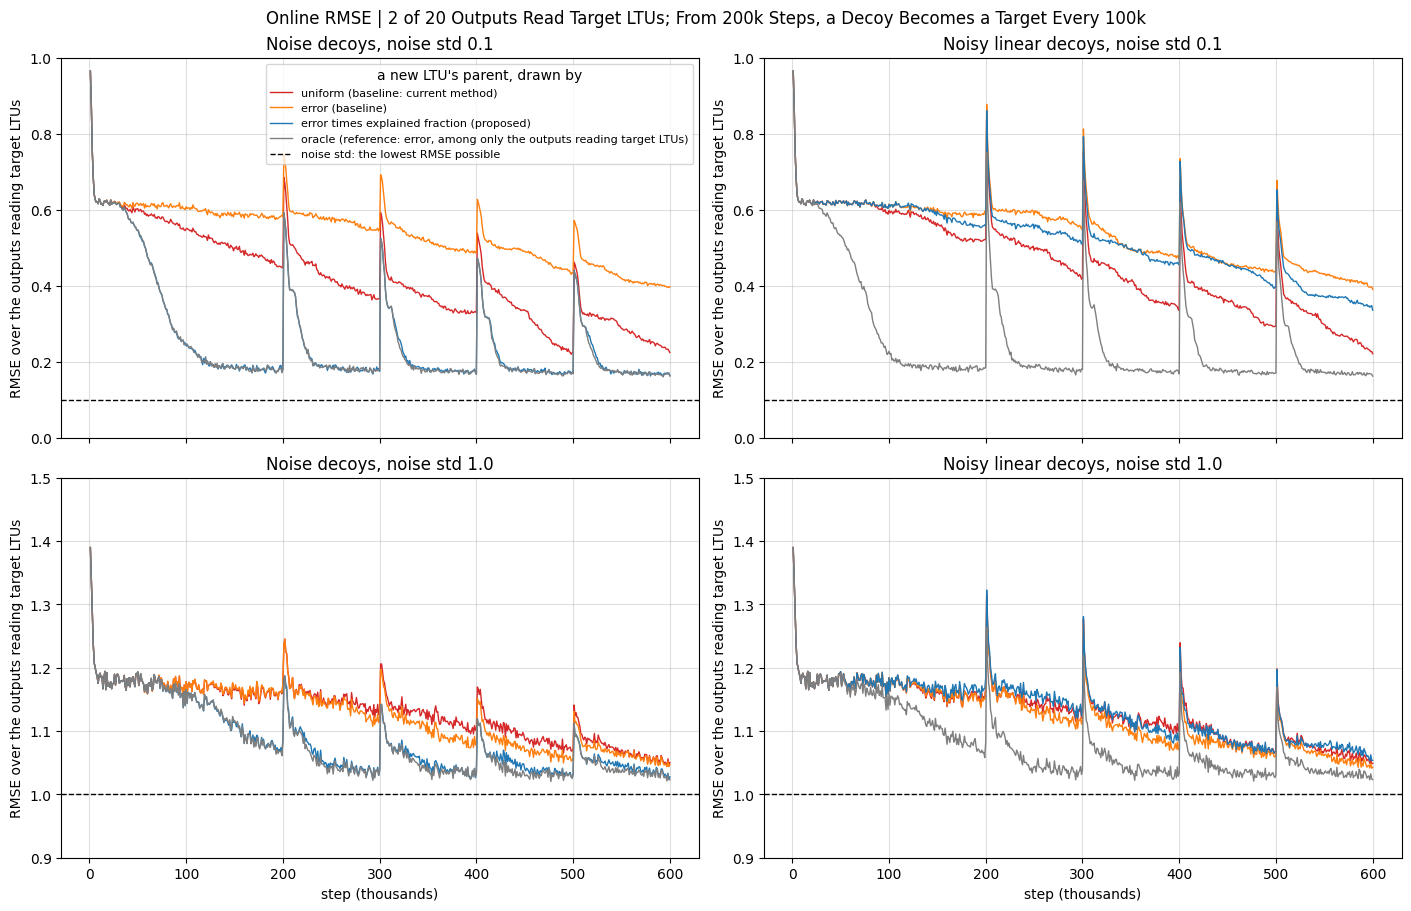

noise decoys, noise std 0.1, RMSE averaged over the run: uniform 0.422, error 0.540, error times explained fraction 0.260, oracle 0.258
noise decoys, noise std 1.0, RMSE averaged over the run: uniform 1.133, error 1.125, error times explained fraction 1.085, oracle 1.081
noisy linear decoys, noise std 0.1, RMSE averaged over the run: uniform 0.462, error 0.542, error times explained fraction 0.521, oracle 0.258
noisy linear decoys, noise std 1.0, RMSE averaged over the run: uniform 1.131, error 1.124, error times explained fraction 1.134, oracle 1.081


In [7]:
YLIMS = [(0, 1.0), (0.9, 1.5)]   # zoomed at noise std 1, where the gaps shrink near the floor
STEPS = (np.arange(NUM_STEPS // WINDOW) + 1) * WINDOW
fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharex=True, layout='constrained')
for column, (kind, decoys) in enumerate(DECOYS):
    for row, (noise, ylim) in enumerate(zip(NOISE_STDS, YLIMS)):
        ax = axes[row, column]
        for name, role, rule, color in RULES:
            ax.plot(STEPS / 1000, results[(kind, noise, rule)].mean(0), color=color, lw=1, label=f'{name} ({role})')
        ax.axhline(noise, color='black', ls='--', lw=1, label='noise std: the lowest RMSE possible')
        ax.set(title=f'{decoys.capitalize()}, noise std {noise}', ylim=ylim,
               ylabel='RMSE over the outputs reading target LTUs')
        ax.grid(alpha=0.4)
for ax in axes[1]:
    ax.set(xlabel='step (thousands)')
axes[0, 0].legend(title="a new LTU's parent, drawn by", fontsize=8)
fig.suptitle('Online RMSE | 2 of 20 Outputs Read Target LTUs; From 200k Steps, a Decoy Becomes a Target Every 100k')
plt.show()

for kind, decoys in DECOYS:
    for noise in NOISE_STDS:
        print(f'{decoys}, noise std {noise}, RMSE averaged over the run: '
              + ', '.join(f'{name} {results[(kind, noise, rule)].mean():.3f}' for name, _, rule, _ in RULES))

## Results

**By error**, search goes to the decoys, because their noise gives them the largest error. With noise std 0.1 on the
targets, parents by error do worse than uniform parents (RMSE averaged over the run 0.540 against 0.422). With noise
std 1, the targets' own noise makes their error as large as the decoys', and parents by error do barely better than
uniform parents (1.125 against 1.133).

**Error times explained fraction** keeps search away from noise decoys. It does as well as the oracle at both noise
levels (0.260 against 0.258, and 1.085 against 1.081), and it finds each decoy that becomes a target as fast as the
oracle.

**Noisy linear decoys fool it.** The linear learner explains half of their variance, but the other half is noise, so
their error times explained fraction stays at about 0.5. Parents by error times explained fraction do worse than
uniform parents (0.521 against 0.462 at noise std 0.1, and 1.134 against 1.131 at noise std 1), and far worse than the
oracle (0.258 and 1.081). From the statistics of an output alone, noise looks the same as error that LTUs can remove.
Only the results of the LTUs tried on an output can show the difference.

## Details

**Target.** Each target LTU outputs the sign (±1) of a sum of its 10 inputs with random ±1 weights. An output reads
its target LTUs with random ±1 weights, scaled to unit variance; a noisy linear decoy's linear function has random ±1
weights on 10 random inputs of its own, scaled likewise. When a decoy becomes a target, it loses its linear part, and its noise
becomes that of the other outputs that read target LTUs.

**Learner.** As in `../step_by_step/4_parent_weights.ipynb`, except that each LTU feeds only its parent: in a network
with thousands of outputs, an LTU cannot feed them all. At step 0, every rule draws the LTUs' parents uniformly, and
the LTUs read random inputs with random signs, as no output has weights yet.

**Measure.** RMSE over the outputs that read target LTUs at that step, over windows of 1k steps, mean over seeds.